In [92]:
import sys
import os
import glob

# Get the absolute path to the parent directory
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Add hybrid_lasso to sys.path
sys.path.append(project_root)

# Now, import should work
from hybrid_lasso.model_ar_reg import AdaptiveRidgeRegression

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from lassonet import LassoNetRegressor
import seaborn as sns
import torch

In [93]:
def save_dataset(X, y, filename, test_ratio=0.5, val_ratio=0.5):
    n_features = X.shape[1]
    feature_names = [f"feature_{i}" for i in range(n_features)]
    X_df = pd.DataFrame(X, columns=feature_names)
    X_df["target"] = y

    # split into train and test
    train_df, test_df = train_test_split(X_df, test_size=test_ratio, random_state=42)
    val_df, test_df = train_test_split(test_df, test_size=val_ratio, random_state=42)

    print(train_df.shape, val_df.shape, test_df.shape)

    # create folders if not exist
    os.makedirs(f"../data/synthetic_reg/{filename}", exist_ok=True)
    train_df.to_csv(f"../data/synthetic_reg/{filename}/train.csv", index=False)
    val_df.to_csv(f"../data/synthetic_reg/{filename}/val.csv", index=False)
    test_df.to_csv(f"../data/synthetic_reg/{filename}/test.csv", index=False)

    return train_df, val_df, test_df

p=3

\begin{equation}
    y = x_1^2 + x_2^2 + x_3^2    
\end{equation}

In [58]:
seed = 42
n = 20000

p = 3

X = np.random.uniform(-2, 2, (n, p))
y = X[:, 0] ** 2 + X[:, 1] ** 2 + X[:, 2] ** 2

y += np.random.normal(0, 1, n)  # add noise

train_df, val_df, test_df = save_dataset(
    X, y, "limitation1_p3_n20000", test_ratio=0.5, val_ratio=0.5
)

(10000, 4) (5000, 4) (5000, 4)


In [95]:
train_df = pd.read_csv("../data/synthetic_reg/limitation1_p3_n20000/train.csv")
val_df = pd.read_csv("../data/synthetic_reg/limitation1_p3_n20000/val.csv")
test_df = pd.read_csv("../data/synthetic_reg/limitation1_p3_n20000/test.csv")

In [59]:
train_df

,feature_0,feature_1,feature_2,target
9434,0.355129,1.351277,-0.216745,2.034532
3614,-0.365410,0.937929,0.534392,0.232659
2108,1.939128,0.746113,0.331485,4.425144
7773,-1.739923,-0.834803,0.692210,4.457281
13529,0.856156,-1.369225,-0.374747,2.202153
...,...,...,...,...
11284,-1.057313,-0.557054,1.857049,5.719735
11964,-1.380671,-0.326208,-0.102917,2.948321
5390,-1.872107,-0.892536,0.370502,4.187886
860,0.031551,0.434713,-1.424066,2.898728


In [60]:
## conduct basis expansion
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)
train_df_poly, val_df_poly, test_df_poly = save_dataset(
    X_poly, y, "limitation1_p3_n20000_poly", test_ratio=0.5, val_ratio=0.5
)

(10000, 10) (5000, 10) (5000, 10)


In [96]:
train_df_poly = pd.read_csv("../data/synthetic_reg/limitation1_p3_n20000_poly/train.csv")
val_df_poly = pd.read_csv("../data/synthetic_reg/limitation1_p3_n20000_poly/val.csv")
test_df_poly = pd.read_csv("../data/synthetic_reg/limitation1_p3_n20000_poly/test.csv")

In [97]:
train_df_poly

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,target
0,0.355129,1.351277,-0.216745,0.126117,0.479878,-0.076973,1.825951,-0.292883,0.046979,2.034532
1,-0.365410,0.937929,0.534392,0.133524,-0.342729,-0.195272,0.879711,0.501222,0.285575,0.232659
2,1.939128,0.746113,0.331485,3.760215,1.446809,0.642792,0.556685,0.247325,0.109882,4.425144
3,-1.739923,-0.834803,0.692210,3.027332,1.452492,-1.204391,0.696895,-0.577858,0.479154,4.457281
4,0.856156,-1.369225,-0.374747,0.733003,-1.172270,-0.320842,1.874777,0.513113,0.140435,2.202153
...,...,...,...,...,...,...,...,...,...,...
9995,-1.057313,-0.557054,1.857049,1.117912,0.588981,-1.963482,0.310309,-1.034476,3.448629,5.719735
9996,-1.380671,-0.326208,-0.102917,1.906252,0.450385,0.142095,0.106411,0.033572,0.010592,2.948321
9997,-1.872107,-0.892536,0.370502,3.504784,1.670922,-0.693619,0.796620,-0.330686,0.137271,4.187886
9998,0.031551,0.434713,-1.424066,0.000995,0.013715,-0.044930,0.188975,-0.619060,2.027965,2.898728


In [98]:
def train_lasso_cv(train_df, test_df, cv=5, alphas=None, fit_intercept=True):
    X_train = train_df.drop(columns="target")
    y_train = train_df["target"]
    X_test = test_df.drop(columns="target")
    y_test = test_df["target"]

    # Create pipeline with scaling and LassoCV
    lasso_pipeline = make_pipeline(
        StandardScaler(),
        LassoCV(
            alphas=alphas, cv=cv, max_iter=10000, random_state=42, fit_intercept=fit_intercept
        ),
    )

    # Fit model
    lasso_pipeline.fit(X_train, y_train)

    # Predict and evaluate
    y_pred = lasso_pipeline.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)

    # Extract best alpha
    best_alpha = lasso_pipeline.named_steps["lassocv"].alpha_

    return lasso_pipeline, best_alpha, mse

In [63]:
def train_lassonet(train_df, val_df, test_df, hidden_dims=(64, 128)):
    X_train = train_df.drop("target", axis=1).values
    y_train = train_df["target"].values
    X_val = val_df.drop("target", axis=1).values
    y_val = val_df["target"].values
    X_test = test_df.drop("target", axis=1).values
    y_test = test_df["target"].values

    model = LassoNetRegressor(
        hidden_dims=hidden_dims,
        verbose=True,
        patience=(100, 5),
        random_state=42,
        torch_seed=42,
    )

    path = model.path(
        X_train,
        y_train,
        X_val=X_val,
        y_val=y_val,
        return_state_dicts=True,
    )

    best_record = min(path, key=lambda rec: rec.val_loss)
    print("Best λ:", best_record.lambda_)
    print("Train MSE:", best_record.loss)
    print("Val   MSE:", best_record.val_loss)
    print("Selected: ", best_record.selected.sum())

    # test
    model.load(best_record.state_dict)
    y_test_pred = model.predict(X_test)
    test_acc = mean_squared_error(y_test, y_test_pred)
    print(f"Test MSE: {test_acc:.3f}")

In [64]:
def plot_lasso_coeff(model, train_df, figsize=(4, 3), name=None):
    # Extract fitted LassoCV model
    lasso = model.named_steps["lassocv"]

    # Print coefficients
    print("Coefficients:", lasso.coef_)
    print("Intercept:", lasso.intercept_)

    # Plot
    plt.figure(figsize=figsize)
    plt.gca().set_axisbelow(True)

    feature_names = train_df.drop(columns="target").columns.tolist() + ["Intercept"]
    coefficients = np.append(lasso.coef_, lasso.intercept_)

    plt.barh(feature_names, coefficients)
    plt.xlabel("Coefficient Value")
    plt.ylabel("Feature Name")
    plt.title("Feature Coefficients of Lasso Regression")
    plt.tight_layout()
    if name is not None:
        plt.savefig(f"../{name}_lasso_coeff.pdf", dpi=300)
    plt.show()

In [65]:
def plot_nimo(ckpt, train_df, figsize1=(4, 3), figsize2=(1, 6), hidden_dim=None, name=None):
    if hidden_dim is None:
        model = AdaptiveRidgeRegression.load_from_checkpoint(ckpt)
    else:
        model = AdaptiveRidgeRegression.load_from_checkpoint(ckpt, hidden_dim=hidden_dim)

    beta = model.beta.detach().cpu().numpy()
    beta_0 = model.beta_0.detach().cpu().numpy()

    plt.figure(figsize=figsize1)
    plt.gca().set_axisbelow(True)

    feature_names = train_df.columns[:-1].tolist() + ["Intercept"]
    coefficients = np.append(beta, beta_0)
    plt.barh(feature_names, coefficients)
    plt.xlabel("Coefficient Value")
    plt.ylabel("Feature Name")
    plt.title("Feature Coefficients of NIMO")
    if name is not None:
        plt.savefig(f"../{name}_nimo_coeff.pdf", dpi=300)
    plt.show()

    # Plot FC layer weights
    first_fc_layer = model.fc1.weight.detach().cpu().numpy()
    first_fc_layer = first_fc_layer[:, : len(train_df.columns) - 1]

    plt.figure(figsize=figsize2)
    plt.imshow(first_fc_layer, aspect="auto", cmap="viridis", vmin=-1, vmax=1)
    plt.colorbar(label="Weight Magnitude")
    plt.title("First FC Layer Weights")
    if first_fc_layer.shape[1] <= 5:
        plt.xticks(ticks=[0, first_fc_layer.shape[1] - 1], labels=[1, first_fc_layer.shape[1]])
    else:
        plt.xticks(
            ticks=np.arange(0, first_fc_layer.shape[1], 5),
            labels=np.arange(1, first_fc_layer.shape[1] + 1, 5),
        )
    plt.xlabel("Input Features")
    plt.ylabel("Neurons")
    if name is not None:
        plt.savefig(f"../{name}_fc_weights.pdf", dpi=300)
    plt.show()

    return coefficients

In [ ]:
def plot_allcoeff_comparison(
    lasso_coeff, nimo_coeff, gt_coeff, name, set_legend=False, set_ylim=True
):
    plt.figure(figsize=(2 * (len(gt_coeff) / 2), 3))
    plt.gca().set_axisbelow(True)

    x = np.arange(len(gt_coeff))
    bar_width = 0.25
    plt.bar(x - bar_width, lasso_coeff, width=bar_width, label="Lasso")
    plt.bar(x, nimo_coeff, width=bar_width, label="NIMO")
    plt.bar(x + bar_width, gt_coeff, width=bar_width, label="Ground Truth")
    plt.grid(axis="y", linestyle="--", alpha=0.7)

    if set_ylim:
        plt.ylim(-3.5, 4)

    x_ticks = [
        f"$x_1$",
        f"$x_2$",
        f"$x_3$",
        f"$x_1^2$",
        f"$x_1 x_2$",
        f"$x_1 x_3$",
        f"$x_2^2$",
        f"$x_2 x_3$",
        f"$x_3^2$",
        f"$intercept$",
    ]
    plt.xticks(x, x_ticks)
    plt.xlabel("Feature Index")
    plt.ylabel("Coefficient Value")
    if set_legend:
        plt.legend()
    plt.tight_layout()
    plt.savefig(f"../{name}_allcoeff.pdf", dpi=300)
    plt.show()

### Train Lasso on original data

Best alpha: 0.0114730387325702
Test MSE: 5.307
Coefficients: [ 0.00000000e+00  0.00000000e+00 -1.84741111e-17]
Intercept: 4.025551034088118


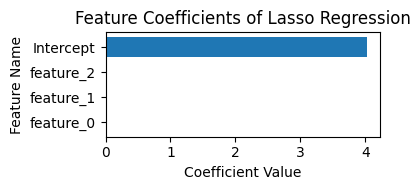

In [83]:
## Train a Lasso model
model, best_alpha, mse = train_lasso_cv(train_df, test_df)

print(f"Best alpha: {best_alpha}")
print(f"Test MSE: {mse:.3f}")

plot_lasso_coeff(model, train_df, figsize=(4, 2))

lasso = model.named_steps["lassocv"]
lasso_coeff = lasso.coef_
lasso_intercept = lasso.intercept_
lasso_coeff = np.append(lasso_coeff, lasso_intercept)

MSE: 5.340
==> training with noise_injection=True
AdaptiveRidgeRegression(
  (fc1): Linear(in_features=5, out_features=64, bias=True)
  (fc2): Linear(in_features=66, out_features=128, bias=True)
  (fc3): Linear(in_features=194, out_features=1, bias=True)
  (dropout2): Identity()
)
==> training with noise_injection=True


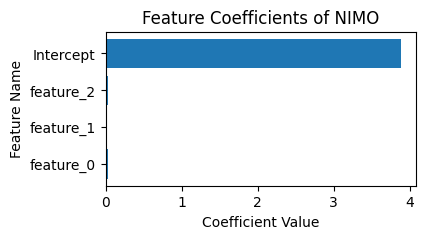

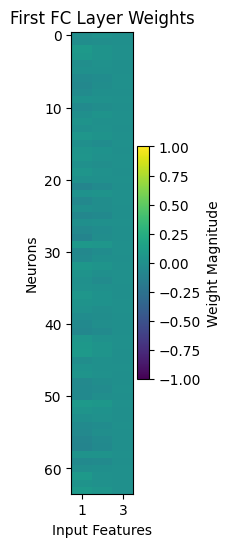

In [84]:
## Train our NIMO model and compare the results
expr_name = "ar_limit1_lp_0.0001"

hybrid_pred = torch.load(f"../ckpts/predictions_{expr_name}.pt")[0]
pred_hybrid = np.array(hybrid_pred)

mse = mean_squared_error(test_df["target"], pred_hybrid)
print(f"MSE: {mse:.3f}")


model_ckpt = "../tb_logs/ar_limit1_lp_0.0001/version_0/checkpoints/best_model_epoch=1495.ckpt"

model = AdaptiveRidgeRegression.load_from_checkpoint(model_ckpt)
print(model)

nimo_coeff = plot_nimo(
    model_ckpt, train_df, figsize1=(4, 2), figsize2=(1, 6), name="limit1_original"
)

In [69]:
## Train LassoNet and compare the results
train_lassonet(train_df, val_df, test_df)

Best λ: 102.77318636349402
Train MSE: 0.9702122807502747
Val   MSE: 1.030171275138855
Selected:  tensor(3)
Test MSE: 1.027


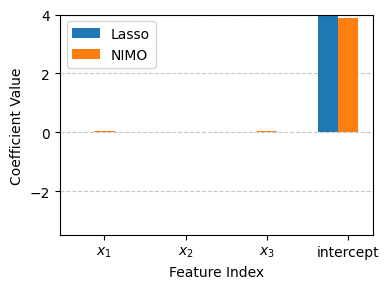

In [85]:
gt_coeff = np.array([0, 0, 0, 0])
plot_allcoeff_comparison(lasso_coeff, nimo_coeff, gt_coeff, name="toy", set_legend=True)

### Train Lasso on basis expanded dataset

Best alpha: 0.003005906423462217
Test MSE: 1.009
Coefficients: [-0.0072016   0.00851208  0.00471381  1.20496971  0.00547566  0.00909933
  1.17920958 -0.00172094  1.20700762]
Intercept: 4.025551034088118


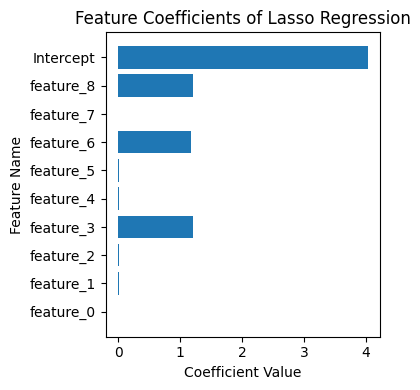

: 

In [ ]:
## Train a Lasso model
model, best_alpha, mse = train_lasso_cv(train_df_poly, test_df_poly, fit_intercept=True)

print(f"Best alpha: {best_alpha}")
print(f"Test MSE: {mse:.3f}")

plot_lasso_coeff(model, train_df_poly, figsize=(4, 4))

lasso = model.named_steps["lassocv"]
lasso_coeff = lasso.coef_
lasso_intercept = lasso.intercept_
lasso_coeff = np.append(lasso_coeff, lasso_intercept)

MSE: 1.009
==> training with noise_injection=True
AdaptiveRidgeRegression(
  (fc1): Linear(in_features=13, out_features=64, bias=True)
  (fc2): Linear(in_features=68, out_features=128, bias=True)
  (fc3): Linear(in_features=196, out_features=1, bias=True)
  (dropout2): Identity()
)
==> training with noise_injection=True


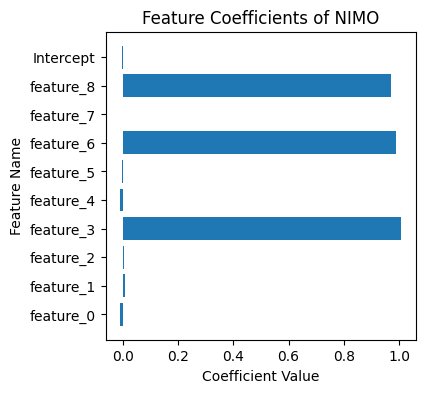

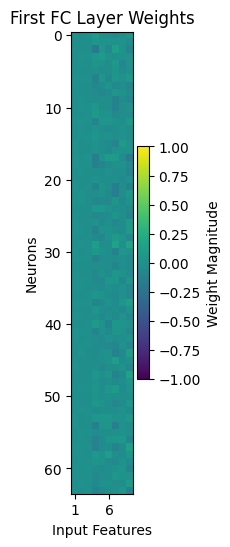

In [91]:
## Train our NIMO model and compare the results
expr_name = "ar_limit1_lp_0.0001_poly"

hybrid_pred = torch.load(f"../ckpts/predictions_{expr_name}.pt")[0]
pred_hybrid = np.array(hybrid_pred)

mse = mean_squared_error(test_df["target"], pred_hybrid)
print(f"MSE: {mse:.3f}")

model_ckpt = "../tb_logs/ar_limit1_lp_0.0001_poly/version_0/checkpoints/best_model_epoch=156.ckpt"

model = AdaptiveRidgeRegression.load_from_checkpoint(model_ckpt)
print(model)

nimo_coeff = plot_nimo(
    model_ckpt, train_df_poly, figsize1=(4, 4), figsize2=(1, 6), name="limit1_poly"
)

In [78]:
## Train LassoNet and compare the results
train_lassonet(train_df_poly, val_df_poly, test_df_poly)

Best λ: 158.8852568188227
Train MSE: 0.9716173410415649
Val   MSE: 1.012014389038086
Selected:  tensor(3)
Test MSE: 1.012


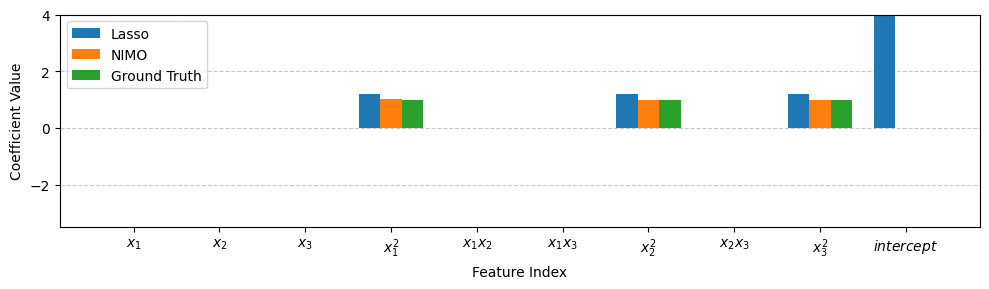

In [90]:
gt_coeff = np.array([0, 0, 0, 1, 0, 0, 1, 0, 1, 0])
plot_allcoeff_comparison(lasso_coeff, nimo_coeff, gt_coeff, name="poly2", set_legend=True)